In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from ucimlrepo import fetch_ucirepo
# fetch dataset
combined_cycle_power_plant = fetch_ucirepo(id=294)
# data (as pandas dataframes)
X = combined_cycle_power_plant.data.features
y = combined_cycle_power_plant.data.targets
# metadata
print(combined_cycle_power_plant.metadata)
# variable information
print(combined_cycle_power_plant.variables)

{'uci_id': 294, 'name': 'Combined Cycle Power Plant', 'repository_url': 'https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant', 'data_url': 'https://archive.ics.uci.edu/static/public/294/data.csv', 'abstract': 'The dataset contains 9568 data points collected from a Combined Cycle Power Plant over 6 years (2006-2011), when the plant was set to work with full load. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 9568, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['PE'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2014, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C5002N', 'creators': ['Pnar Tfekci', 'Heysem Kaya'], 'intro_paper': {'ID': 406, 'type': 'NATIVE', 'title': 'Prediction of full load electrical power output of a base load operated combined cycle power plant using machine learning methods', 'aut

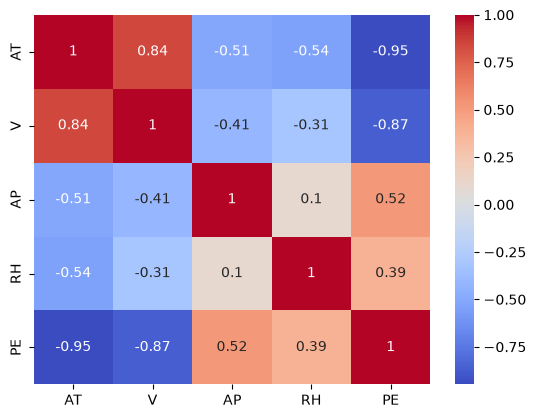

          AT         V        AP        RH        PE
AT  1.000000  0.844107 -0.507549 -0.542535 -0.948128
V   0.844107  1.000000 -0.413502 -0.312187 -0.869780
AP -0.507549 -0.413502  1.000000  0.099574  0.518429
RH -0.542535 -0.312187  0.099574  1.000000  0.389794
PE -0.948128 -0.869780  0.518429  0.389794  1.000000


In [4]:
df = combined_cycle_power_plant.data.original
corr = df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()
print(corr)

### Análise da correlação em relação a variável Target

Podemos Observar que as variáveis que possuem maior influência sobre a variável Target
 são AT(Temperatura Ambiente) e V(Vácuo). A correlação nos permite intuir que para temperaturas mais elevadas e altos níveis de cm Hg a produção de energia será menor. AP(Pressão Atmosférica) e RH(Umidade Relativa) tem correlação positiva em magnitudes menores.

___

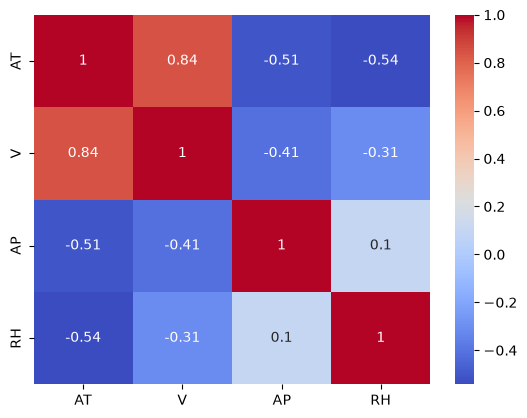

In [5]:
corr = X.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

A Figura acima no mostra que V(Vácuo) e AT(Temperatura Atmosférica) possuem alta correlação positiva


In [6]:
print(y.describe())

                PE
count  9568.000000
mean    454.365009
std      17.066995
min     420.260000
25%     439.750000
50%     451.550000
75%     468.430000
max     495.760000


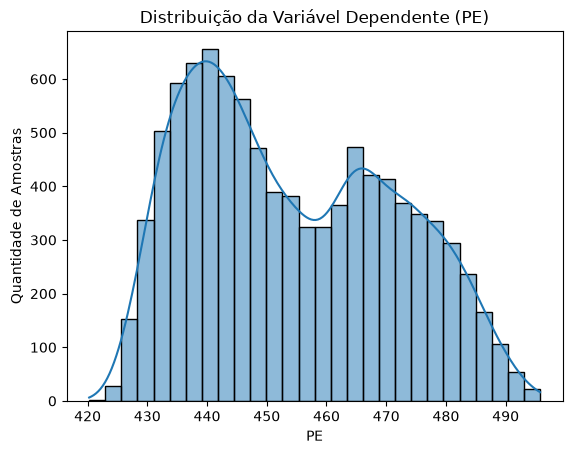

In [7]:
sns.histplot(data=y, x='PE', kde=True)
plt.ylabel('Quantidade de Amostras')
plt.xlabel('PE')
plt.title('Distribuição da Variável Dependente (PE)')
plt.show()

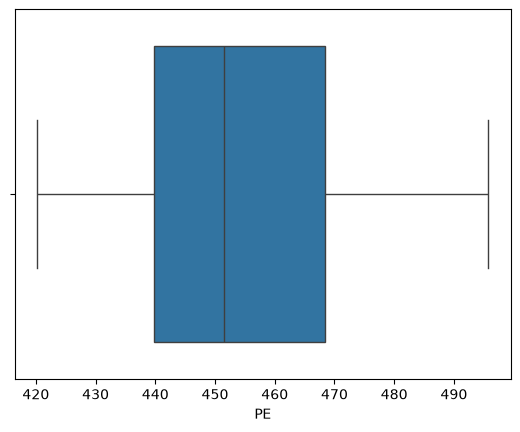

In [8]:
sns.boxplot(x='PE', data=y)
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
)

print(f"Tamanho do dataset = {X.shape[0]} amostras")
print(f"Quantidade de amostras de treinamento = {X_train.shape[0]} amostras")
print(f"Quantidade de amostras de teste = {X_test.shape[0]} amostras")

Tamanho do dataset = 9568 amostras
Quantidade de amostras de treinamento = 7654 amostras
Quantidade de amostras de teste = 1914 amostras


In [10]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

df_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
df_scaled.head()

,AT,V,AP,RH
0,0.595852,0.420996,0.405840,0.842946
1,0.274963,0.268149,0.806236,0.658949
2,0.197926,0.253559,0.696857,0.831844
3,0.285037,0.345552,0.508290,0.760222
4,0.458370,0.260320,0.351398,0.649201


In [11]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 4)","[[-67.02,-13.04, 2.51,-11.68]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[502.69]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[28.76,15.58,11.02, 6.09]"


In [12]:
theta = model.coef_
theta

array([[-67.0241147 , -13.04365905,   2.51349834, -11.67857974]])

In [13]:
theta0 = model.intercept_
theta0

array([502.68791318])

In [14]:
y_pred = model.predict(X_test_scaled)

from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

r2 = r2_score(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Coeficiente de determinação: {r2:.2f}\nRaiz do erro quadrático médio: {rmse:.2f}\nErro médio absoluto: {mae:.2f}")

Coeficiente de determinação: 0.93
Raiz do erro quadrático médio: 4.50
Erro médio absoluto: 3.60


o modelo apresenta um desempenho satisfatório para prever a produção de energia de uma usina de ciclo combinado. O coeficiente de determinação de 0,93 indica que o modelo consegue explicar grande parte da variação da variável dependente, a raiz do erro quadrático médio penaliza erros maiores, indicando que o modelo apresenta erros de previsão relativamente baixos em comparação com produção de energia do conjunto de dados, enquanto o erro médio absoluto indica que em média as previsões do modelo diferem dos valores reais em aproximadamente 3,60 MW.

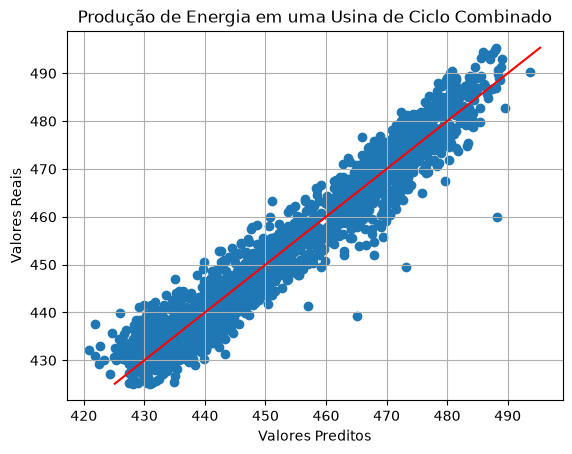

In [15]:
import numpy as np
y_test_min = np.min(y_test)
y_test_max = np.max(y_test)
y_ideal = np.linspace(y_test_min, y_test_max, 1000)

plt.plot(y_ideal, y_ideal, 'r')
plt.scatter(y_pred, y_test)
plt.xlabel("Valores Preditos")
plt.ylabel("Valores Reais")
plt.title("Produção de Energia em uma Usina de Ciclo Combinado")
plt.grid()
plt.show()